# Are the network profiles stable enough to use?

**Himanshu Jadaun | Project 03 | November 9, 2026**

This is unsupervised ML: finding descriptive county-level patterns without ground-truth segment labels. The new technique is bootstrap-stable segmentation with frozen temporal transfer. Scientific practices include source identity and geospatial auditing, development-only preprocessing/model selection, conditional tile-resampling uncertainty, aggregation sensitivity, and later-quarter replication.

The full study executes in `study.py` (or `run_study.py`). This notebook executes explanations and independently recomputes its saved evidence; its cells do not claim to fit the complete 200-replicate study.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
from IPython.display import display, Image
from sklearn.metrics import adjusted_rand_score
from study import load_snapshot,aggregate,matrix
R=Path('results')
tiles,context=load_snapshot()
profiles=pd.read_csv(R/'county_profiles.csv',dtype={'GEOID':str})
metrics=json.loads((R/'metrics.json').read_text())
display(pd.DataFrame(json.loads((R/'data_audit.json').read_text())).T)
display(context.head())

,bbox_tiles,invalid_metric_tiles,assigned_colorado_tiles,unassigned_after_validation,tests,sum_tile_device_counts_not_unique_people
2025Q4,7942,2,7937,3,33640,12572
2026Q1,7316,2,7312,2,32102,11622


,GEOID,NAME,ALAND,POPESTIMATE2024,population_density_km2
0,08067,La Plata,4376255274,56823,12.984389
1,08059,Jefferson,1979762077,578533,292.223498
2,08065,Lake,976215866,7369,7.548535
3,08055,Huerfano,4120756305,6988,1.695805
4,08033,Dolores,2763958508,2467,0.892560


## 1. Establish the geography, time and sampling unit

Observed foundation: Speedtest by Ookla mobile-test tiles in Colorado for 2025 Q4, with 2026 Q1 reserved for replication. A point-in-polygon join assigns each tile centroid to 2024 Census county boundaries in EPSG:4326. The 2024 Census population estimates join by five-character county GEOID; they supply background density only, not an ML feature or a test-weighting denominator.

These are self-selected tests, aggregated within tiles. Summed device counts are not unique devices across tiles or people. Unobserved land cannot be labelled a coverage gap from this source. Publication snapshots can be revised by Ookla; file hashes identify this extract. Census API key requirements were handled by using official bulk estimates, with no fabricated replacements.

2025Q4 tiles: 7937 tests: 33640 eligible counties: 51
2026Q1 tiles: 7312 tests: 32102 eligible counties: 45


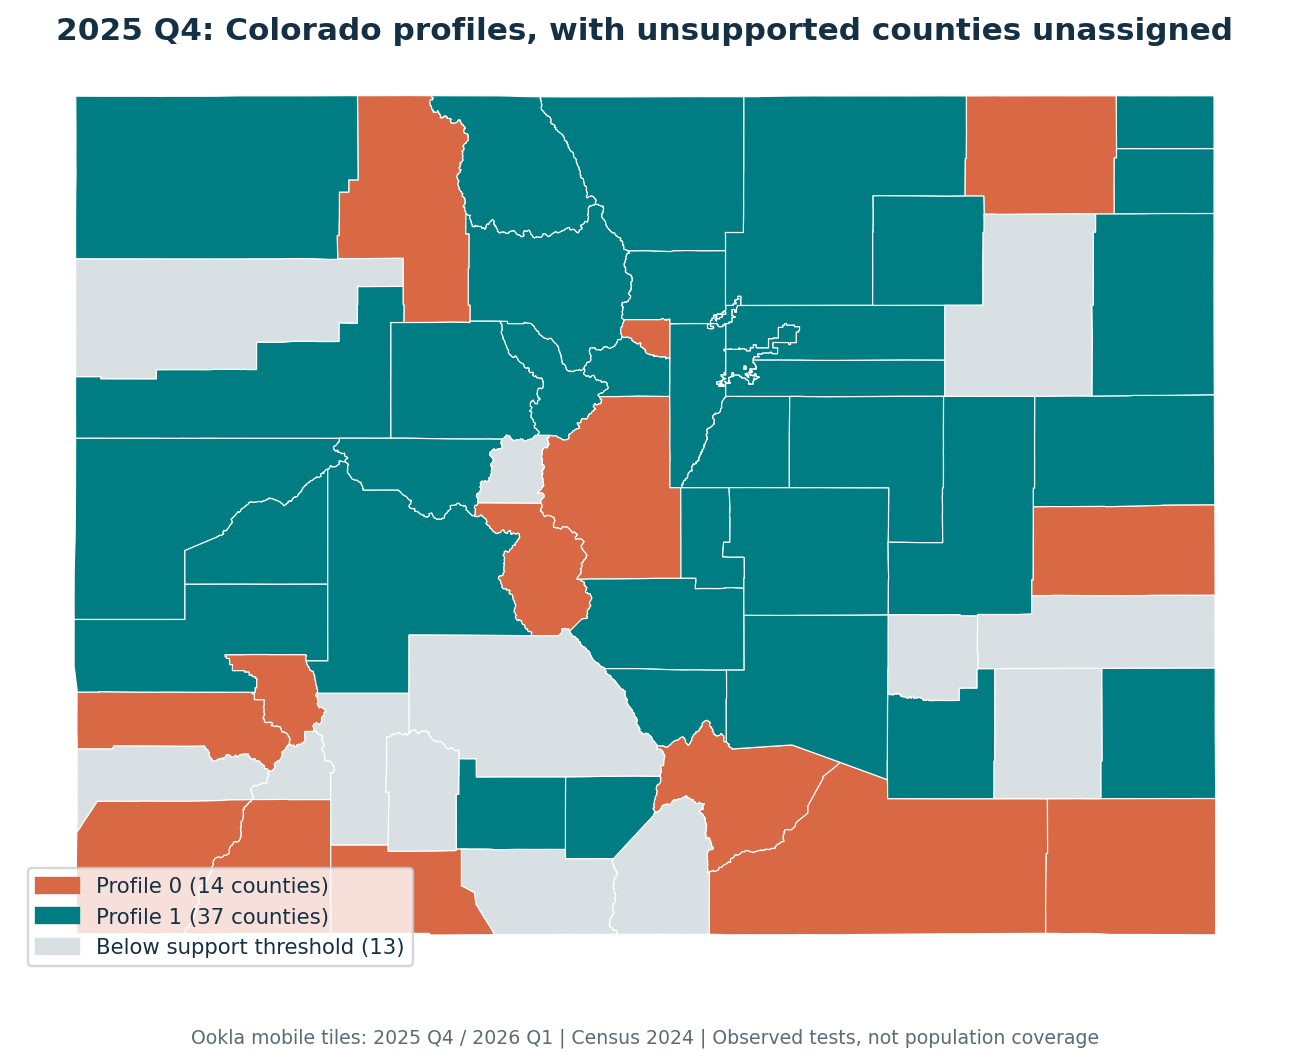

In [2]:
for quarter,f in tiles.items():
    summary=aggregate(f)
    print(quarter, 'tiles:',len(f),'tests:',int(f.tests.sum()),
          'eligible counties:',int(summary.eligible.sum()))
    assert summary.tests.sum()==f.tests.sum()
display(Image('figures/01_profile_map.png'))

## 2. Specify the target of aggregation

Primary county summaries weight each published tile mean by its test count. Download/upload are converted from kilobits/s to megabits/s. This approximates a mean over observed tests, subject to source rounding; it does not estimate the mean experience of every resident.

Eligibility requires at least five observed tiles and 25 tests in a quarter. The development set contains 51 counties, rather than all 64. Bootstrap resamples preserve the original eligible county set, even when resampled test totals vary.

K-means uses log1p download, upload and latency, standardized on development counties only. Population density and county names stay outside the feature matrix. Every county has equal influence in the clustering step after its own summary is constructed.

In [3]:
selection=json.loads((R/'selection_locked_before_replication.json').read_text())
development=aggregate(tiles['2025Q4']).query('eligible')
np.testing.assert_allclose(matrix(development).mean(axis=0),selection['scaler_mean'])
display(json.loads((R/'single_profile_baseline.json').read_text()))
display(pd.read_csv(R/'k_selection.csv'))
print('Frozen K:',selection['selected_k'],'replication selected K:',selection['replication_used_for_selection'])

Frozen K: 2 replication selected K: False


{'statewide_county_median': {'download_mbps': 225.9662962962963,
  'upload_mbps': 22.133698355601236,
  'latency_ms': 33.153225806451616},
 'single_profile_standardized_sse': 153.0,
 'selected_inertia': 90.14140897933636,
 'warning': 'In-sample reconstruction falls mechanically with K; not an out-of-sample prediction gain. K=1 silhouette is undefined.'}

,k,silhouette,min_cluster_counties,inertia,allowed
0,2,0.419799,14,90.141409,True
1,3,0.412774,4,66.089144,False
2,4,0.304571,4,53.612037,False
3,5,0.299662,1,44.096650,False


## 3. Compare segmentation to a simple reference

The one-profile reference describes a statewide county median and total standardized squared dispersion. K=1 has no silhouette score. K-means candidates use K=2,3,4,5; a candidate must leave at least five counties in every cluster. Select the highest development silhouette among candidates that pass the support gate. A silhouette below 0.25 would retain a no-segmentation interpretation.

K=2 passes with silhouette 0.420 and cluster sizes 14/37. The other candidates create clusters below the support floor. Labels are ordered by increasing download centroid solely for readability. No causal meaning or natural customer taxonomy follows from a cluster number. Lower training inertia with more clusters is mechanical, not a held-out prediction gain.

,profile,counties,tiles,tests,median_download_mbps,median_upload_mbps,median_latency_ms,median_population_density_km2,median_membership_frequency
0,0,14,558,1302,133.661,11.823,48.903,3.874,0.915
1,1,37,7264,32176,257.468,24.208,31.758,8.917,0.975


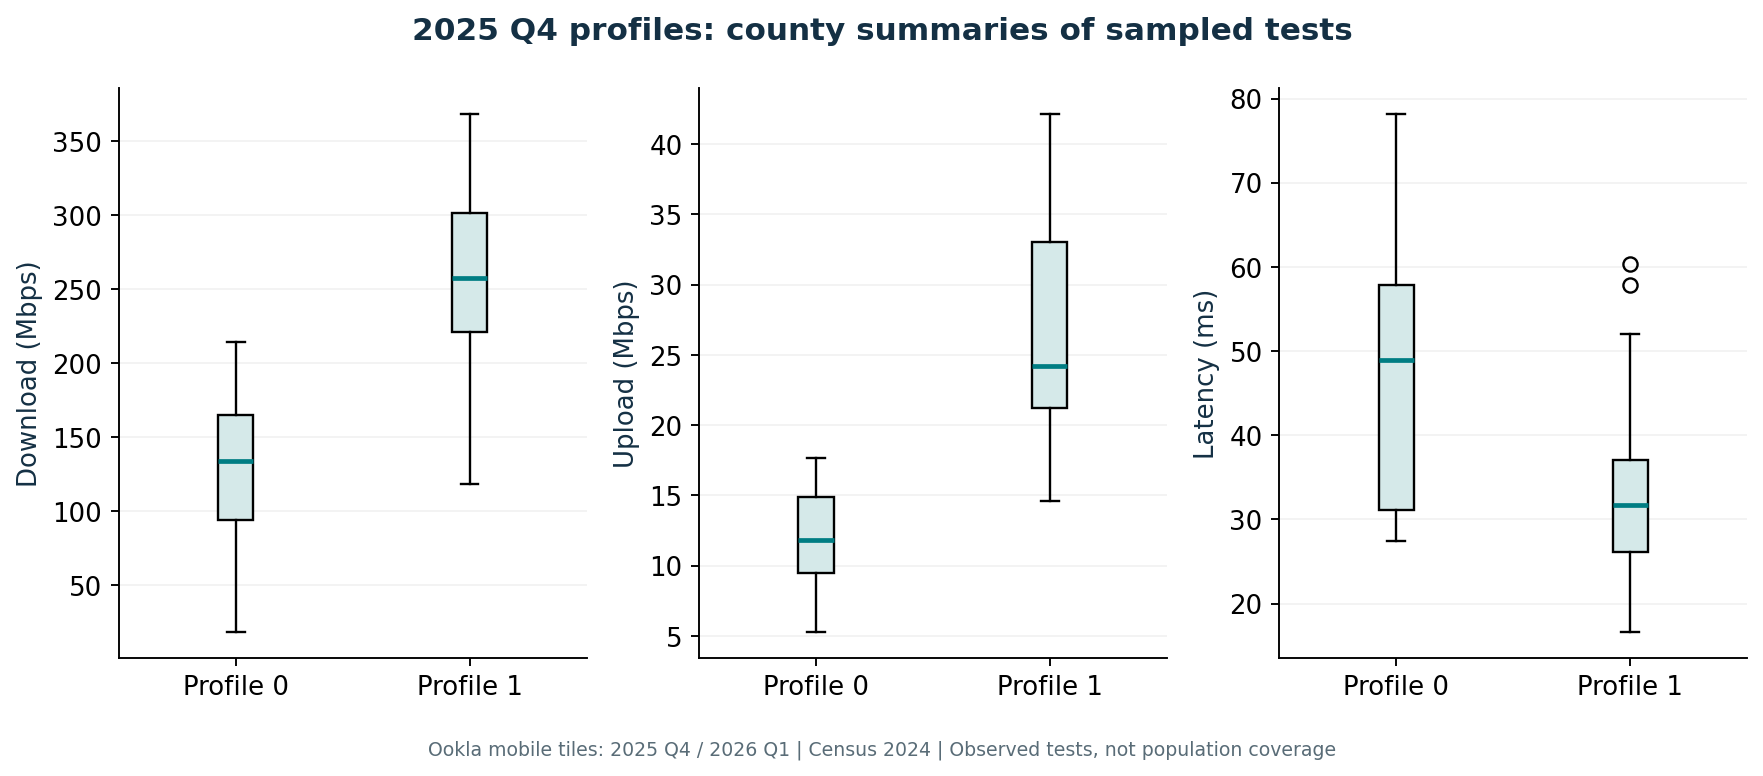

In [4]:
display(pd.read_csv(R/'profile_summary.csv').round(3))
display(Image('figures/02_network_profiles.png'))

## 4. Resample observations and align labels

For each of 200 replicates, sample observed tiles with replacement within each eligible development county, recompute county summaries, and refit the scaler and selected K. Align the refitted labels to the reference using a maximum-overlap Hungarian assignment. ARI is permutation invariant; membership frequencies need explicit alignment.

The resulting distribution is conditional on the observed tiles, fixed county set, K and source snapshot. Neighboring tiles can be dependent, and individual test variability is already lost in aggregation. These frequencies are not probabilities that a county has a true population segment, and their percentile range is not a population confidence interval.

Median ARI: 0.630679149224054
Conditional 2.5/97.5 percentiles: [0.3569572854802124, 0.918113436332715]
Counties with membership frequency >= 80%: 39 / 51


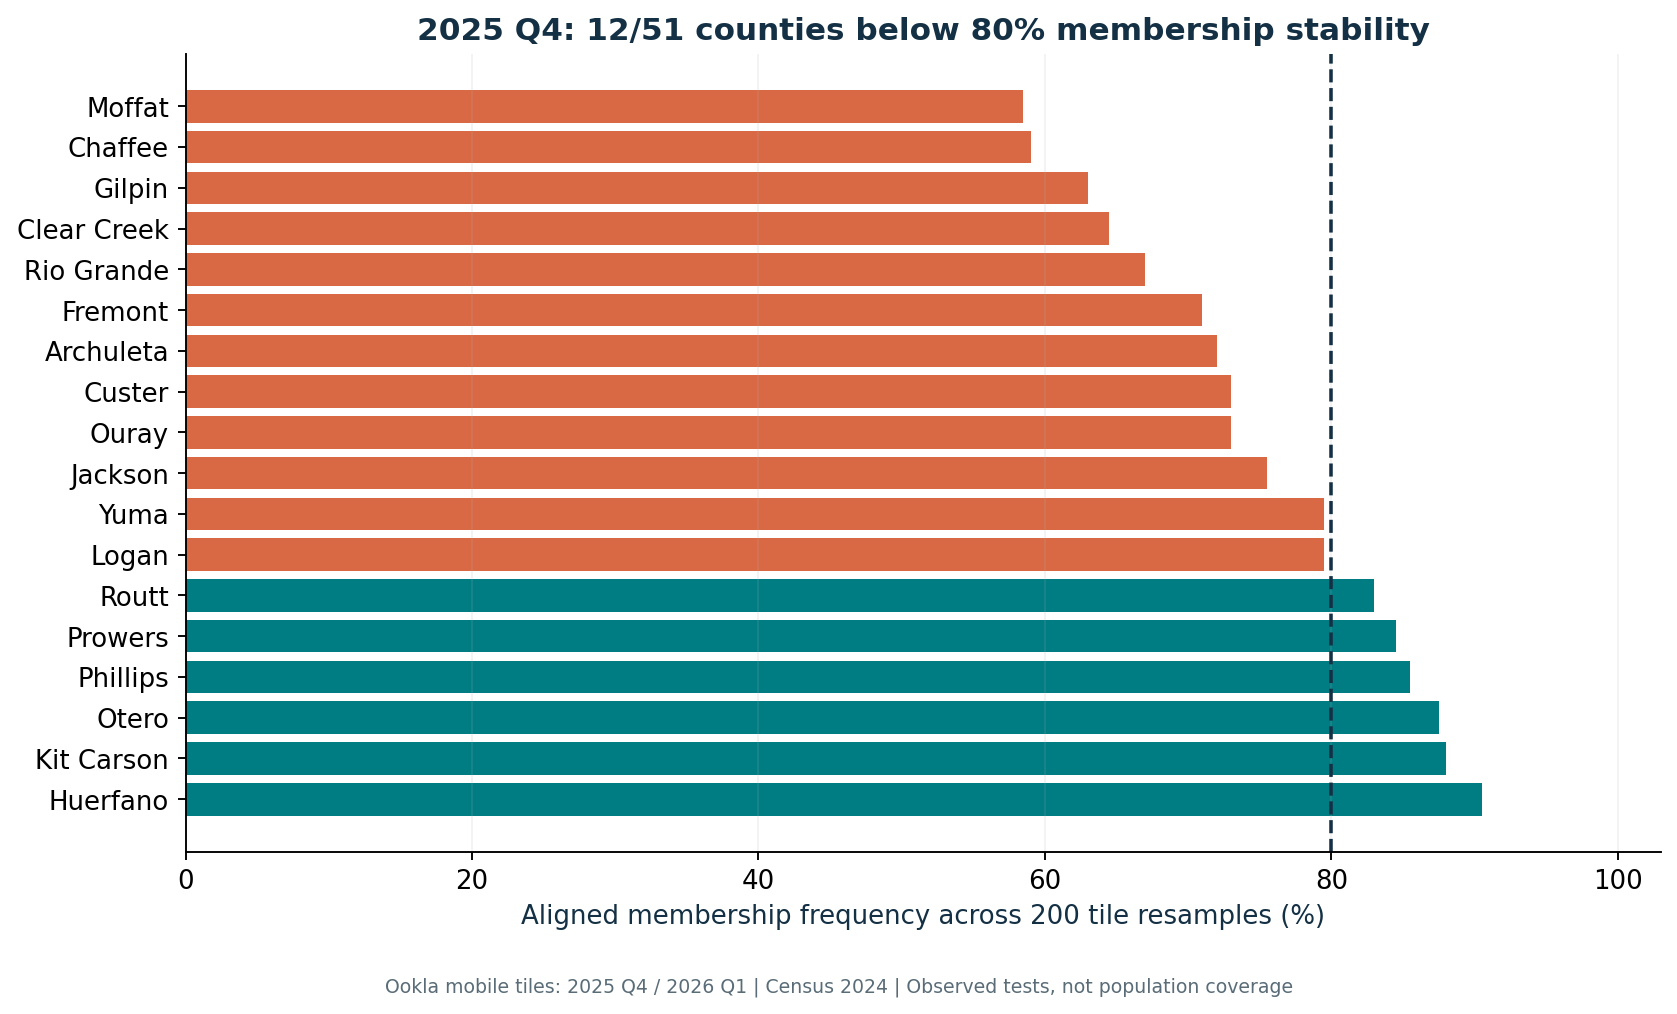

In [5]:
b=pd.read_csv(R/'bootstrap_stability.csv')
print('Median ARI:',b.ari.median())
print('Conditional 2.5/97.5 percentiles:',b.ari.quantile([.025,.975]).to_list())
print('Counties with membership frequency >= 80%:',int((profiles.bootstrap_membership_frequency>=.8).sum()),'/',len(profiles))
display(Image('figures/03_membership_stability.png'))

## 5. Test temporal transfer with the model frozen

Development preprocessing, centroids and K remain frozen. Assign eligible 2026 Q1 counties, then compare the same county identifiers across periods. These are repeat county summaries, not the same subscribers. The transition table is a stability diagnostic, not supervised accuracy.

36/43 counties retain their profile, but the smaller profile retains only 6/12. ARI of 0.395 reveals a weaker partition correspondence than raw agreement alone suggests. A matched-quadkey analysis partially controls spatial sample turnover, while test weights and users can still change within the matched tiles.

Same-profile fraction: 0.8372093023255814
ARI: 0.3947721179624665


next_profile,0,1
profile,,
0,6,6
1,1,30


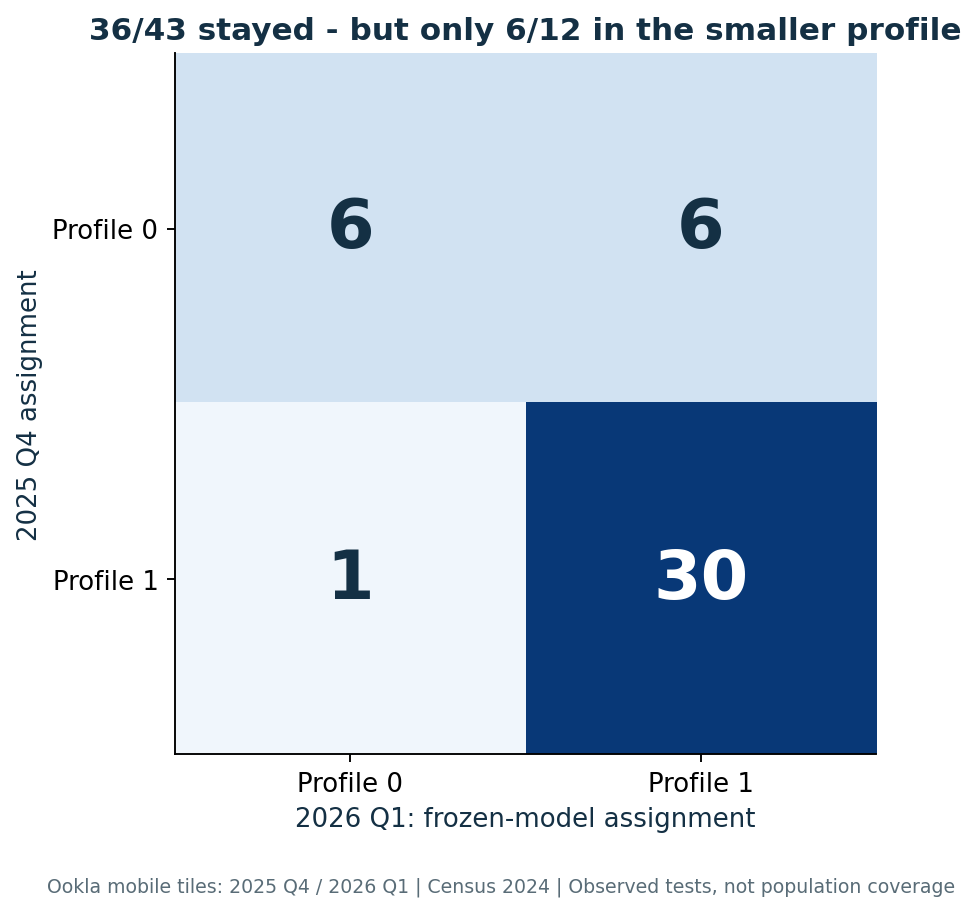

In [6]:
t=pd.read_csv(R/'temporal_assignments.csv')
display(pd.crosstab(t.profile,t.next_profile))
print('Same-profile fraction:',(t.profile==t.next_profile).mean())
print('ARI:',adjusted_rand_score(t.profile,t.next_profile))
display(Image('figures/04_quarter_transfer.png'))

## 6. Change an important modelling assumption

Equal-tile aggregation asks about sampled locations, whereas test weighting emphasizes test activity. Frozen-model assignment changes for 7/51 counties under this alternative. Requiring five tests per tile retains only 23 eligible counties, so its 91.3% same-profile rate cannot be directly compared as though all 51 counties remained. Matched-quarter comparisons have yet another eligible set.

Ward hierarchical clustering on the same standardized development features gives ARI 0.843 against K-means. This is algorithm sensitivity on the same observations, not independent confirmation.

Matched tiles: 3294 eligible matched counties: 31
Matched-tile same-profile fraction: 0.8387096774193549
Matched-tile ARI: 0.16436273154547967


,variant,counties,same_profile_fraction,ari,method
0,equal_tile,51,0.862745,0.508260,Frozen primary scaler and centroids; changing ...
1,minimum_5_tests_per_tile,23,0.913043,0.547252,Frozen primary scaler and centroids; changing ...


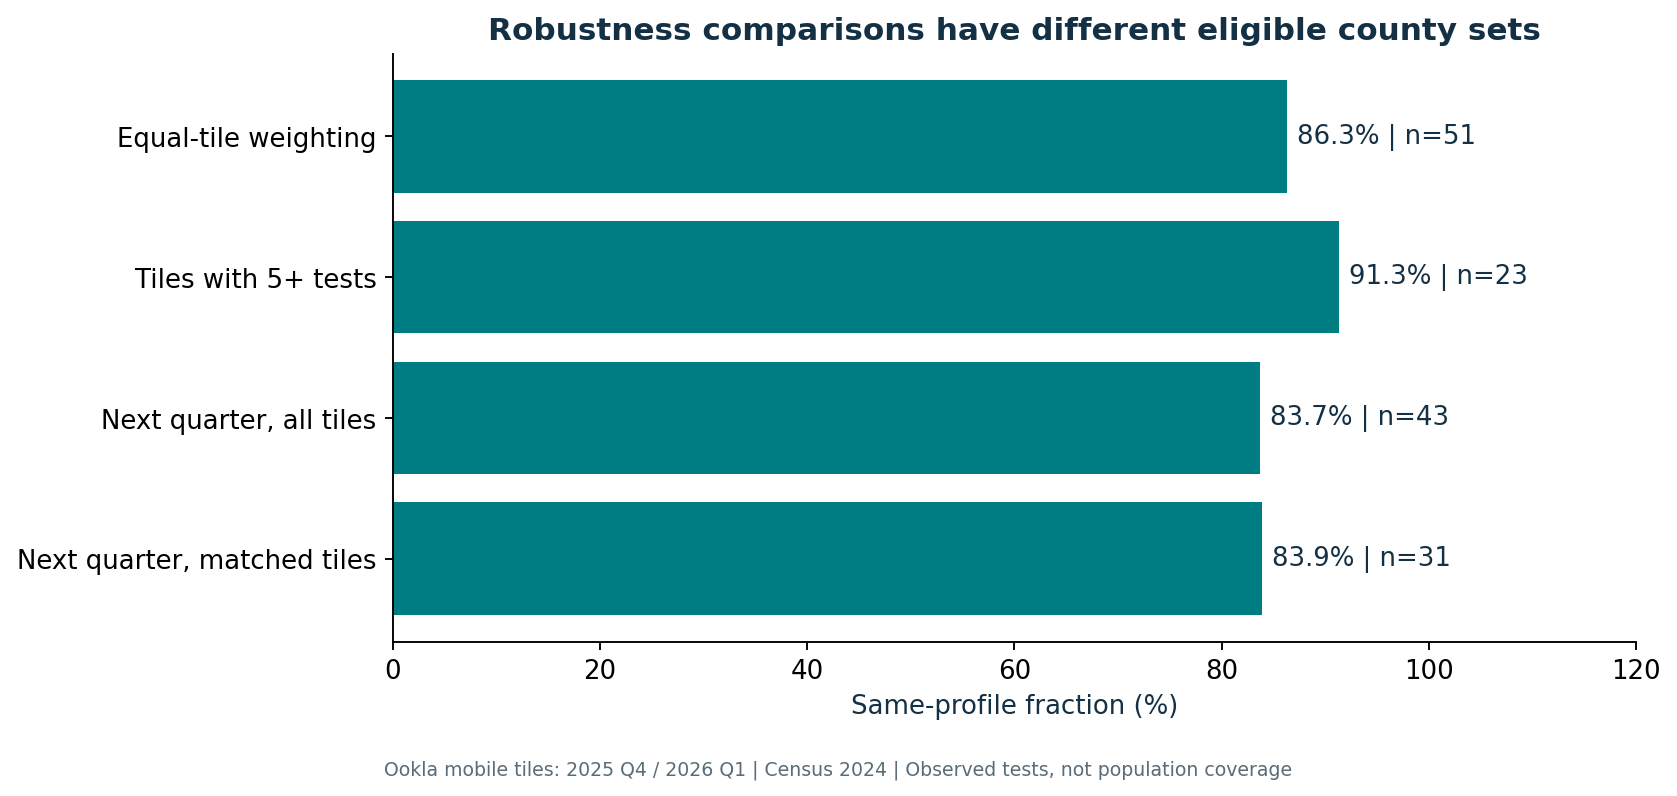

In [7]:
display(pd.read_csv(R/'aggregation_sensitivity.csv'))
print('Matched tiles:',metrics['matched_tiles'],'eligible matched counties:',metrics['matched_tile_counties'])
print('Matched-tile same-profile fraction:',metrics['matched_tile_same_profile_fraction'])
print('Matched-tile ARI:',metrics['matched_tile_ari'])
display(Image('figures/05_sensitivity.png'))

## 7. Use Census context without ecological overreach

2024 population estimates divided by 2024 county land area are background density estimates. They are not contemporaneous network measurements or individual attributes, and no population-weighted performance estimate is made. K-means does not see the density column. Observed density differences between profiles do not identify why speeds differ.

Source input identities:


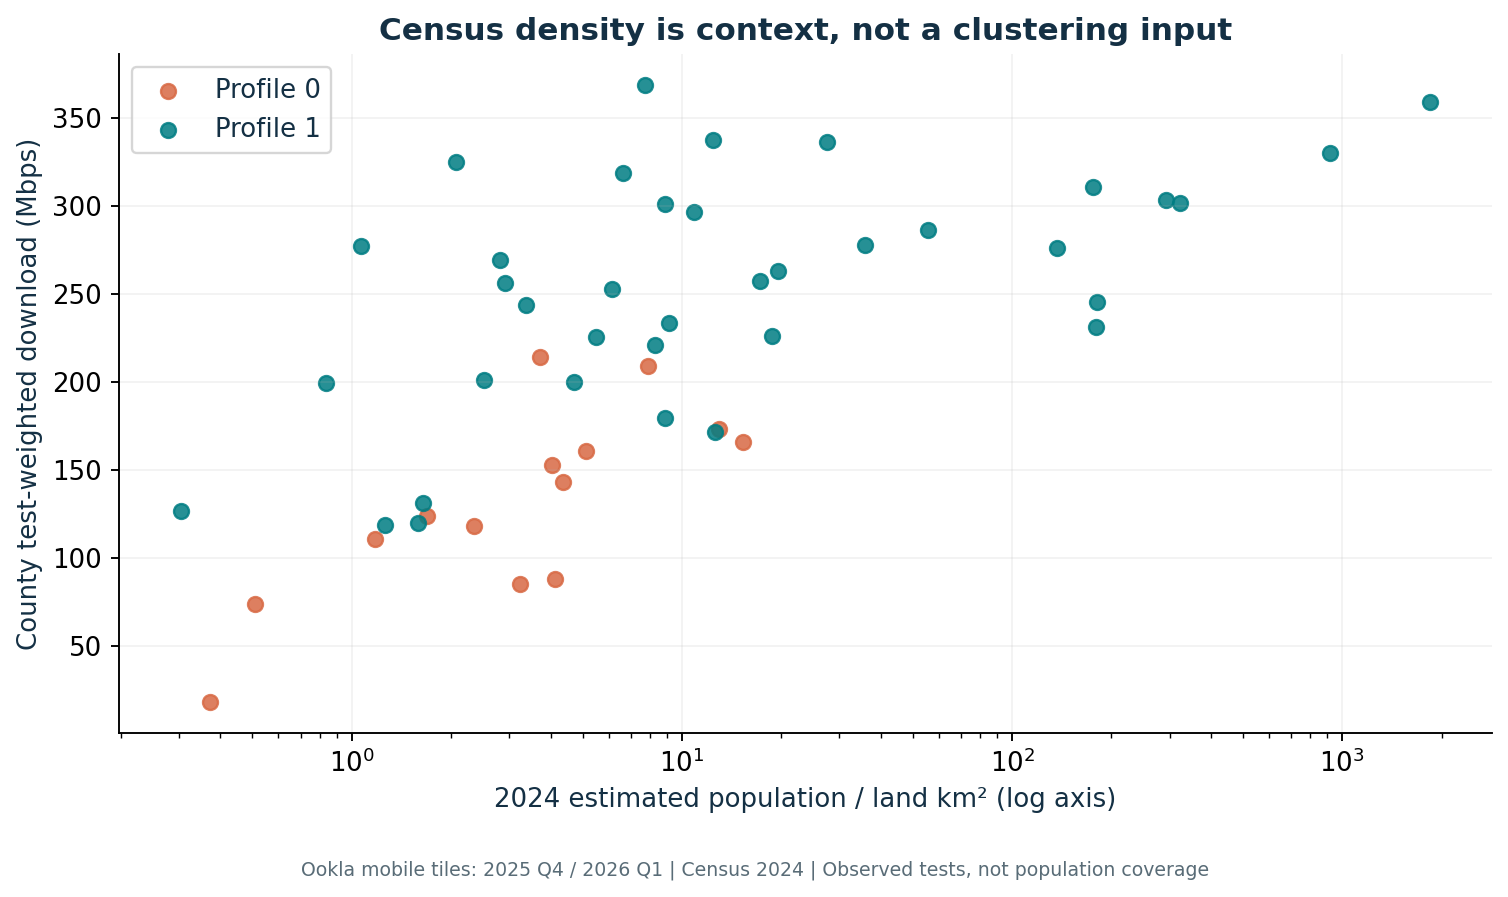

{'county_boundaries.geojson': 'bbed78ca2e195b8d0fc6c4aac6f207c87bb42a1a7db9e1db5247da4d06676854',
 'county_context.csv': '1bb7b734755959408592ce6b9980a595d47f29d3bbb1ae28614513644c697037',
 'tiles_2025Q4.csv.gz': '35cf9bdeb43befb2d59ebf11b827f1424ea77f6ad2c69b8d1cdbb00ffec28d2c',
 'tiles_2026Q1.csv.gz': 'd44c81daf81a016bfa71313d23a175704ebb7bcbddd741162ef416a30e2812c1'}

In [8]:
display(Image('figures/06_population_context.png'))
print('Source input identities:')
display(json.loads((R/'source_manifest.json').read_text())['snapshot_hashes'])

## Decision and ownership

Use the profiles as descriptive hypotheses for additional measurement, while flagging counties with unstable membership or insufficient observations. The smaller profile's temporal movement and weighting sensitivity argue against hard market labels, carrier ranking, customer targeting or coverage promises.

Next evidence: future quarters, spatial-block resampling, boundary-assignment sensitivity, and a sampling design that measures unobserved locations. Do not convert these tiles into churn, causal network effects or employer outcomes.

**Ownership exercise:** preserve this release, replace the within-county IID tile bootstrap with spatial blocks, choose block dimensions before scoring later data, and explain how the stability distribution changes. Read the builder's guide for a two-hour entry path, daily extensions and interview defense.

Data attribution: based on Himanshu Jadaun's analysis of Speedtest by Ookla Global Fixed and Mobile Network Performance Maps for 2025 Q4 and 2026 Q1, accessed November 9, 2026; CC BY-NC-SA 4.0. Census 2024 boundaries and population estimates are U.S. government public-domain sources.